In [1]:
%load_ext autoreload
%autoreload 2

[PyTorch Tutorial](https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html)

# Imports

In [1]:
from src.app import run
from src.game import Screen, Game, StateMember
from src.config.enums import Direction
from src.ai.memory import ReplayMemory, Transition

C:\Users\alast\dev\uni-dev\mat502-ai\mat501-coursework-project\.venv\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [2]:
import math
import random
import matplotlib
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_squared_log_error
from itertools import count
from tqdm import tqdm
import seaborn as sns

# Config

In [3]:
pd.options.display.max_columns = 100

# Functions

In [4]:
def create_input_row(_current_snake_index, _state, _reward, _direction, _column_names):
    _row = {k: 0 for k in _column_names}
    for i in range(len(_state)-5):
        _row[i] = _state[i]

    for _direction_member in list(Direction):
        for _statemember in list(StateMember):
            if _current_snake_index == 0:
                if (_statemember == StateMember.SNAKE0):
                    statemember_text = "MY_BODY"
                elif (_statemember == StateMember.SNAKE1):
                    statemember_text = "OTHER_SNAKE_BODY"
                elif (_statemember == StateMember.SNAKE1_HEAD):
                    statemember_text = "OTHER_SNAKE_HEAD"
                elif (_statemember == StateMember.SNAKE0_HEAD):
                    continue
                else:
                    statemember_text = str(_statemember.name)
                assert(statemember_text != StateMember.SNAKE0_HEAD.name)
            else:
                if (_statemember == StateMember.SNAKE1):
                    statemember_text = "MY_BODY"
                elif (_statemember == StateMember.SNAKE0):
                    statemember_text = "OTHER_SNAKE_BODY"
                elif (_statemember == StateMember.SNAKE0_HEAD):
                    statemember_text = "OTHER_SNAKE_HEAD"
                elif (_statemember == StateMember.SNAKE1_HEAD):
                    continue
                else:
                    statemember_text = str(_statemember.name)
                assert(statemember_text != StateMember.SNAKE1_HEAD.name)
            _row[f"is_state_at_head_offset_{str(_direction_member.value)}_{statemember_text}"] = 0

    _statemember = None
    
    for i, _direction_member in zip(range(len(_state)-5,len(_state)-1), list(Direction)):
        if _current_snake_index == 0:
            if (_state[i] == StateMember.SNAKE0):
                statemember_text = "MY_BODY"
            elif (_state[i] == StateMember.SNAKE1):
                statemember_text = "OTHER_SNAKE_BODY"
            elif (_state[i] == StateMember.SNAKE1_HEAD):
                statemember_text = "OTHER_SNAKE_HEAD"
            else:
                statemember_text = str(_state[i].name)
            assert(statemember_text != StateMember.SNAKE0_HEAD.name)
        else:
            if (_state[i] == StateMember.SNAKE1):
                statemember_text = "MY_BODY"
            elif (_state[i] == StateMember.SNAKE0):
                statemember_text = "OTHER_SNAKE_BODY"
            elif (_state[i] == StateMember.SNAKE0_HEAD):
                statemember_text = "OTHER_SNAKE_HEAD"
            else:
                statemember_text = str(_state[i].name)
            assert(statemember_text != StateMember.SNAKE1_HEAD.name)
        _row[f"is_state_at_head_offset_{str(_direction_member.value)}_{statemember_text}"] = 1
    
    _row[f"current_{_state[-1].name}"] = 1
    _row[f"input_{_direction.name}"] = 1
    _row["reward"] = _reward
    return _row

# Training

In [5]:
is_draw_enabled = False
framerate = 0

screen = Screen(is_draw_enabled=False)
game = Game(
    screen,
    "MAT501 - Coursework",
    is_draw_enabled=False,
    framerate=0,
)
state = game.training_ai_get_current_snake_state()
data_cols = (
    list(range(len(state)-1)) + 
    [f"input_{direction.name}" for direction in list(Direction)] + 
    [f"current_{direction.name}" for direction in list(Direction)] + 
    ["reward"]
            )
data = pd.DataFrame(columns=data_cols)

num_episodes = 2000
MAX_STEPS = 50
for i_episode in tqdm(range(num_episodes), ncols=100, position=0, leave=False):
    screen = Screen(is_draw_enabled=is_draw_enabled)
    game = Game(
        screen,
        "MAT501 - Coursework",
        is_draw_enabled=is_draw_enabled,
        framerate=framerate,
    )
    game_over = False
    for t in count():
        if t > MAX_STEPS:
            break
            
        game.training_ai_frame()
        for snake_idx in range(2):

            direction = list(Direction)[random.randint(0, len(list(Direction))-1)]
            state = game.training_ai_get_current_snake_state()
            observation, reward, game_over = game.training_ai_step(direction)
            
            row = create_input_row(snake_idx, state, reward, direction, data.columns)
    
            if len(data) > 0:
                data = pd.concat([data, pd.DataFrame([row])], ignore_index=True)
            else:
                data = pd.DataFrame([row])

            if game_over:
                break
        if game_over:
            break
        game.training_ai_end_frame()

N Rows: 108605
R2: 0.992
RMSE: 0.002
MAE: 0.024


<Axes: ylabel='Frequency'>

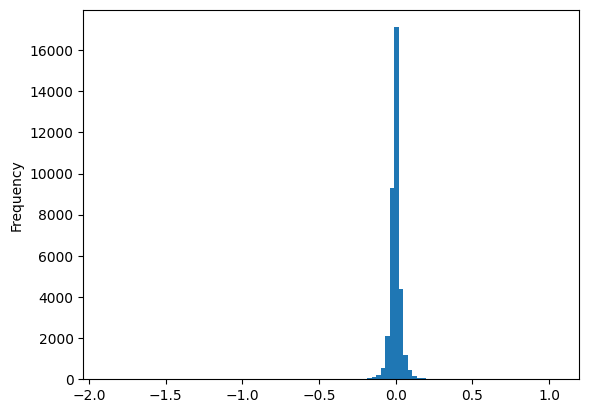

In [6]:
x_cols = [col for col in data.columns if col != "reward"]
y_col = ["reward"]
X_train, X_test, y_train, y_test = train_test_split(data[x_cols], data[y_col], test_size=0.33)
mdl = XGBRegressor(n_estimators=100)
mdl.fit(X_train, y_train)
predictions = mdl.predict(X_test)
print(f"N Rows: {len(data)}")
print(f"R2: {r2_score(y_test, predictions):.3f}")
print(f"RMSE: {mean_squared_error(y_test, predictions):.3f}")
print(f"MAE: {mean_absolute_error(y_test, predictions):.3f}")
pd.Series(y_test.values.reshape(-1)-predictions).plot(kind='hist', bins=100)

In [8]:
mdl.save_model("./models/xgboost_random_simulations_only.ubj")

quite a few outliers, need to explore where it's bad

In [8]:
RANDOM_MOVE_RATE = 0.00
num_episodes = 100
MAX_STEPS = 1000
for i_episode in tqdm(range(num_episodes), ncols=100, position=0, leave=False):
    screen = Screen(is_draw_enabled=False)
    game = Game(
        screen,
        "MAT501 - Coursework",
        is_draw_enabled=False,
        framerate=0,
    )
    game_over = False
    
    for t in count():
        if t > MAX_STEPS:
            break
            
        game.training_ai_frame()
        for snake_idx in range(2):
    
            state = game.training_ai_get_current_snake_state()
            input_rows = []
            for direction in list(Direction):
                input_row = create_input_row(snake_idx, state, reward, direction, data.columns)
                input_rows.append(input_row)
            input_rows = pd.DataFrame(input_rows).drop("reward", axis=1)
    
            if random.random() > RANDOM_MOVE_RATE:
                direction = list(Direction)[mdl.predict(input_rows).argmax()]
            else:
                direction = list(Direction)[random.randint(0, len(list(Direction))-1)]
            
            observation, reward, game_over = game.training_ai_step(direction)
        
            row = create_input_row(snake_idx, state, reward, direction, data.columns)
            
            if len(data) > 0:
                data = pd.concat([data, pd.DataFrame([row])], ignore_index=True)
            else:
                data = pd.DataFrame([row])

            if game_over:
                break
            
        game.training_ai_end_frame()
        if game_over:
            break

In [17]:
import matplotlib

In [18]:
matplotlib.axes.Axes

matplotlib.axes._axes.Axes

matplotlib.axes._axes.Axes

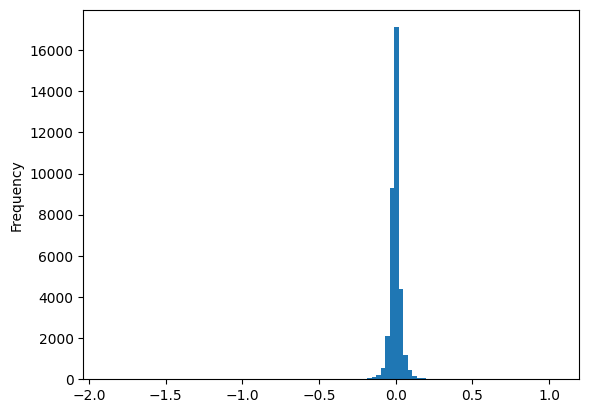

In [16]:
type(pd.Series(y_test.values.reshape(-1)-predictions).plot(kind='hist', bins=100))

N Rows: 126928
R2: 0.982
RMSE: 0.005
MAE: 0.038


<Axes: ylabel='Frequency'>

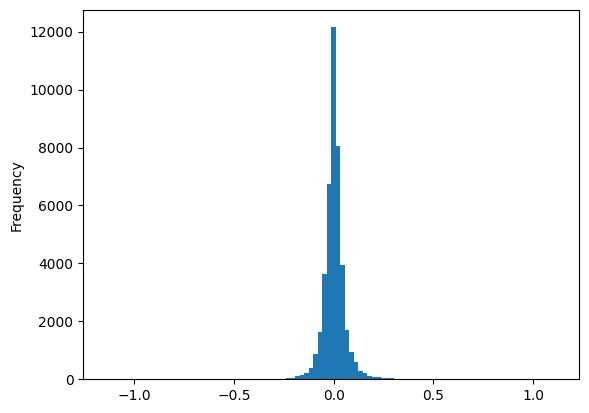

In [9]:
N_UPSAMPLES = 2

x_cols = [col for col in data.columns if col != "reward"]
y_col = ["reward"]
best_rewards_index = data[(data[y_col[0]] == 1.0)].index

upsampled_data = data.copy(deep=True)
for i in range(N_UPSAMPLES):
    upsampled_data = pd.concat([data, upsampled_data.iloc[best_rewards_index]], ignore_index=True)
# upsampled_data = upsampled_data.sample(10_000)

X_train, X_test, y_train, y_test = train_test_split(upsampled_data[x_cols], upsampled_data[y_col], test_size=0.33, shuffle=True)
mdl = XGBRegressor(n_estimators=100)
mdl.fit(X_train, y_train)
predictions = mdl.predict(X_test)
print(f"N Rows: {len(data)}")
print(f"R2: {r2_score(y_test, predictions):.3f}")
print(f"RMSE: {mean_squared_error(y_test, predictions):.3f}")
print(f"MAE: {mean_absolute_error(y_test, predictions):.3f}")
pd.Series(y_test.values.reshape(-1)-predictions).plot(kind='hist', bins=100)

# Test

In [9]:
RANDOM_MOVE_RATE = 0.1
num_episodes = 200
MAX_STEPS = 10_000
screen = Screen(is_draw_enabled=True)
game = Game(
    screen,
    "MAT501 - Coursework",
    is_draw_enabled=True,
    framerate=4,
)
game_over = False

for t in count():
    if t > MAX_STEPS:
        break
        
    game.training_ai_frame()
    for snake_idx in range(2):
        state = game.training_ai_get_current_snake_state()
        input_rows = []
        for direction in list(Direction):
            input_row = create_input_row(snake_idx, state, 0, direction, data.columns)
            input_rows.append(input_row)
        input_rows = pd.DataFrame(input_rows).drop("reward", axis=1)
        direction = list(Direction)[mdl.predict(input_rows).argmax()]
        observation, reward, game_over = game.training_ai_step(direction)

        if game_over:
            break
        
    if game_over:
        break
    game.training_ai_end_frame()

In [12]:
mdl.save_model("./models/xgboost.ubj")

In [48]:
type(mdl)

xgboost.sklearn.XGBRegressor

In [25]:
input_rows

,0,1,2,3,4,5,input_UP,input_DOWN,input_LEFT,input_RIGHT,current_UP,current_DOWN,current_LEFT,current_RIGHT
0,0.25,0.25,0.2,0.0,-0.05,0.0,1,0,0,0,0,1,0,0
1,0.25,0.25,0.2,0.0,-0.05,0.0,0,1,0,0,0,1,0,0
2,0.25,0.25,0.2,0.0,-0.05,0.0,0,0,1,0,0,1,0,0
3,0.25,0.25,0.2,0.0,-0.05,0.0,0,0,0,1,0,1,0,0


In [91]:
game.quit()

False